# Phần 1: Khởi tạo và Khám phá dữ liệu (EDA)

### Khai báo thư viện và Đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style cho biểu đồ
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Đọc dữ liệu
df = pd.read_csv('iot_telemetry_data.csv')

# Hiển thị 5 dòng đầu và thông tin tổng quan
display(df.head())
print(df.info())

,ts,device,co,humidity,light,lpg,motion,smoke,temp
0,1.594512e+09,b8:27:eb:bf:9d:51,0.004956,51.000000,False,0.007651,False,0.020411,22.700000
1,1.594512e+09,00:0f:00:70:91:0a,0.002840,76.000000,False,0.005114,False,0.013275,19.700001
2,1.594512e+09,b8:27:eb:bf:9d:51,0.004976,50.900000,False,0.007673,False,0.020475,22.600000
3,1.594512e+09,1c:bf:ce:15:ec:4d,0.004403,76.800003,True,0.007023,False,0.018628,27.000000
4,1.594512e+09,b8:27:eb:bf:9d:51,0.004967,50.900000,False,0.007664,False,0.020448,22.600000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 405184 entries, 0 to 405183
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ts        405184 non-null  float64
 1   device    405184 non-null  object 
 2   co        405184 non-null  float64
 3   humidity  405184 non-null  float64
 4   light     405184 non-null  bool   
 5   lpg       405184 non-null  float64
 6   motion    405184 non-null  bool   
 7   smoke     405184 non-null  float64
 8   temp      405184 non-null  float64
dtypes: bool(2), float64(6), object(1)
memory usage: 22.4+ MB
None


### Thống kê mô tả chi tiết (Statistics)

In [2]:
# Chọn các cột dữ liệu số quan trọng
numerical_cols = ['temp', 'humidity', 'co', 'lpg', 'smoke']

# Tính toán các chỉ số thống kê mô tả mở rộng
stats_df = df[numerical_cols].describe().T          # chuyển vị bảng thống kê
stats_df['median'] = df[numerical_cols].median()
stats_df['skewness'] = df[numerical_cols].skew()        # sau để đánh giá phân phối dữ liệu
stats_df['kurtosis'] = df[numerical_cols].kurt()

# Sắp xếp lại cột cho dễ nhìn
cols_order = ['count', 'mean', 'median', 'std', 'min', 'max', 'skewness', 'kurtosis']       # ko cần hiện 3 phân vị
stats_df = stats_df[cols_order]

print("Bảng thống kê mô tả chi tiết:")
display(stats_df)

Bảng thống kê mô tả chi tiết:


,count,mean,median,std,min,max,skewness,kurtosis
temp,405184.0,22.453987,22.200000,2.698347,0.000000,30.600000,0.590865,1.217351
humidity,405184.0,60.511694,54.900000,11.366489,1.100000,99.900002,0.521110,-1.256239
co,405184.0,0.004639,0.004812,0.001250,0.001171,0.014420,0.240467,2.927057
lpg,405184.0,0.007237,0.007489,0.001444,0.002693,0.016567,-0.201398,1.763110
smoke,405184.0,0.019264,0.019950,0.004086,0.006692,0.046590,-0.126782,1.892901


### Trực quan hóa phân phối và Nhiễu (Histogram & Boxplot)
vẽ biểu đồ để thấy rõ dữ liệu bị lệch hay chuẩn, và phát hiện các giá trị ngoại lai (Outliers) bằng mắt thường trước khi xử lý.

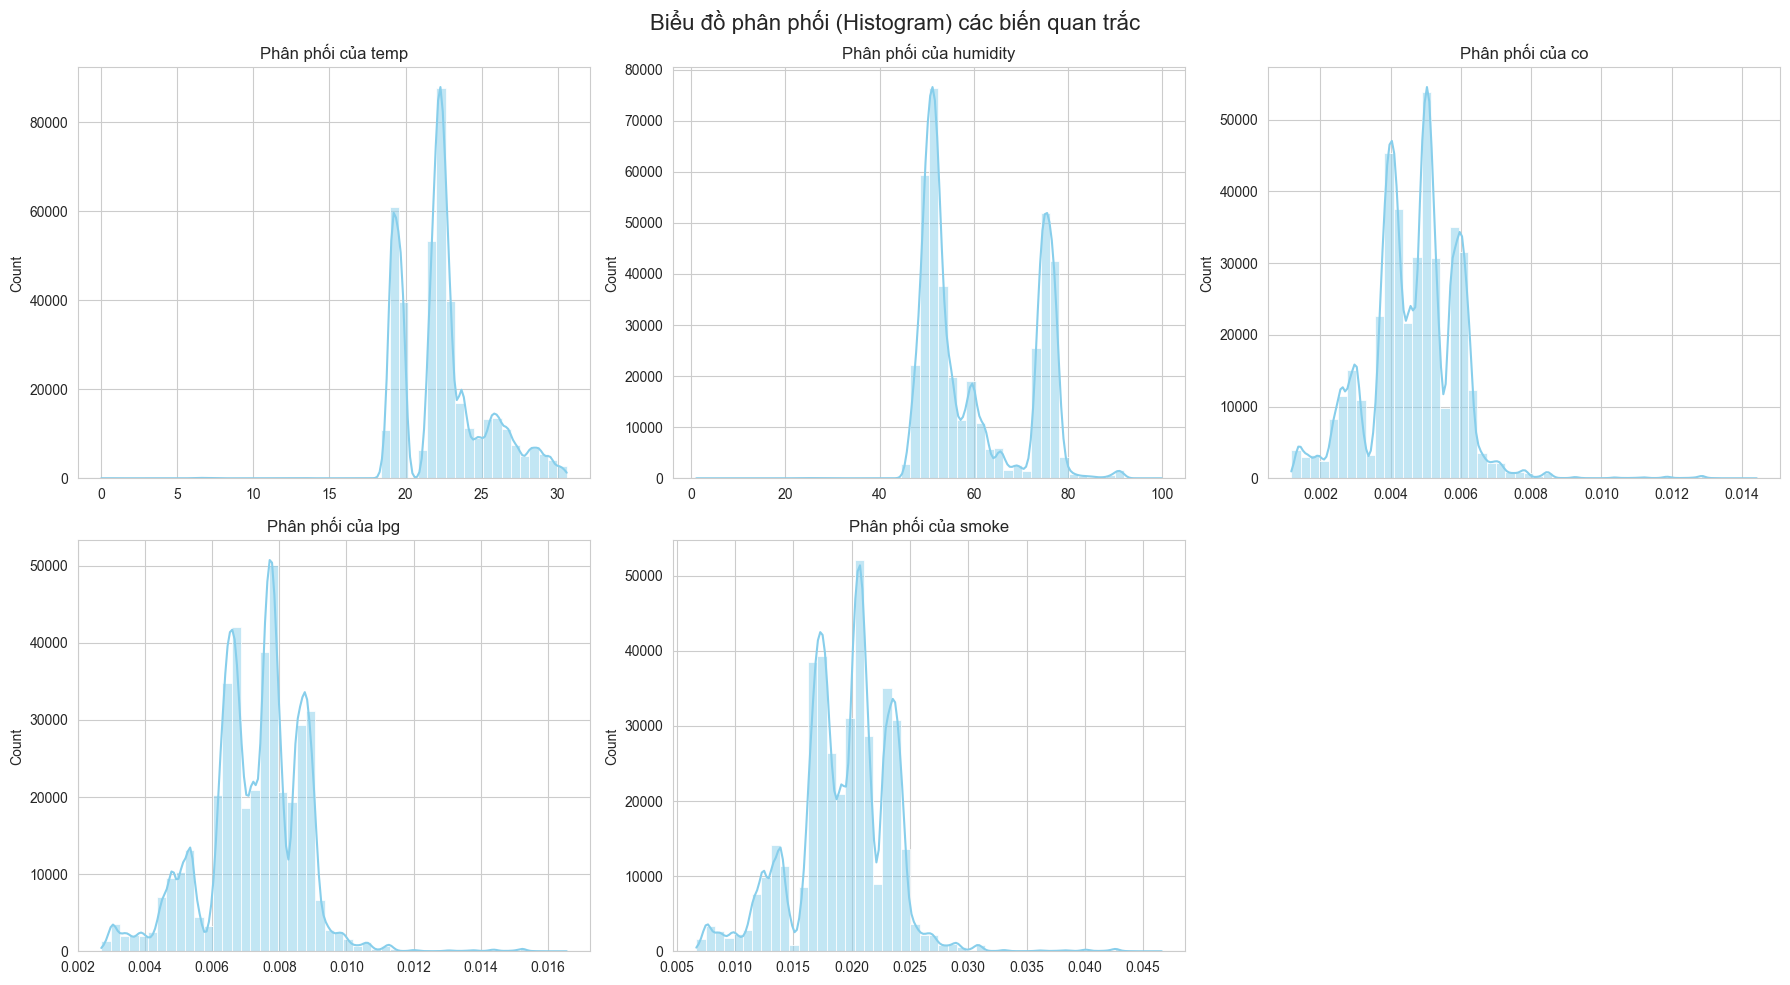

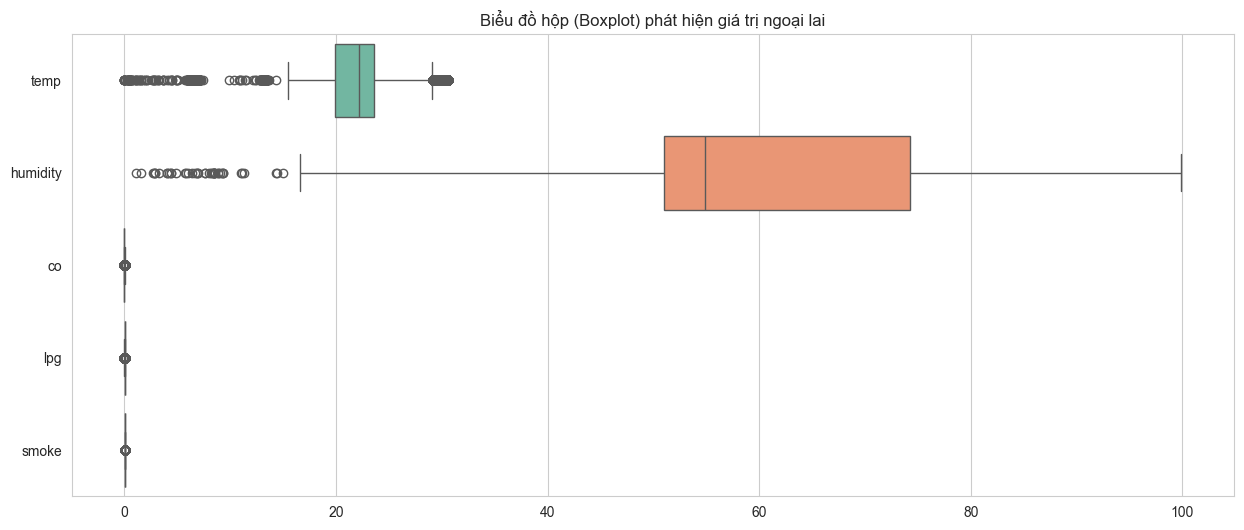

In [3]:
# Vẽ Histogram để xem phân phối dữ liệu
fig, axes = plt.subplots(2, 3, figsize=(18, 10))    # fig là cả cái ảnh to, axes là danh sách 6 cái ô nhỏ bên trong
fig.suptitle('Biểu đồ phân phối (Histogram) các biến quan trắc', fontsize=16)

axes = axes.flatten() # Duyệt Mảng: duỗi thẳng dạng ma trận [[ô1, ô2, ô3], [ô4, ô5, ô6]] ra thành [ô1, ô2, ô3, ô4, ô5, ô6] để dễ dùng vòng lặp
for i, col in enumerate(numerical_cols):    # enumerate giúp biết vừa chạy đến cột nào (col) và đang ở lượt thứ mấy (i)
    sns.histplot(df[col], kde=True, ax=axes[i], bins=50, color='skyblue')   # kde=True: vẽ thêm đường thể hiện mật độ phân phối của dữ liệu
    axes[i].set_title(f'Phân phối của {col}')
    axes[i].set_xlabel('')

# Xóa subplot thừa nếu có
if len(numerical_cols) < len(axes):     # Nếu số cột dữ liệu (5) nhỏ hơn số ô tranh (6)
    fig.delaxes(axes[-1])               # Xóa (delete) cái ô cuối cùng (axes[-1])

plt.tight_layout()      # tự động chỉnh khoảng cách giữa các ô để chữ không bị đè lên nhau.
plt.show()

# Vẽ Boxplot để nhận diện giá trị ngoại lai (Outliers)
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[numerical_cols], orient='h', palette="Set2")	# (..., boxplot sẽ nằm ngang, ...)
plt.title('Biểu đồ hộp (Boxplot) phát hiện giá trị ngoại lai')
plt.show()

### Phân tích tương quan (Correlation Matrix)
bước quan trọng để quyết định giảm chiều dữ liệu. Nếu các biến có màu đỏ đậm (gần 1), chứng tỏ chúng dư thừa.

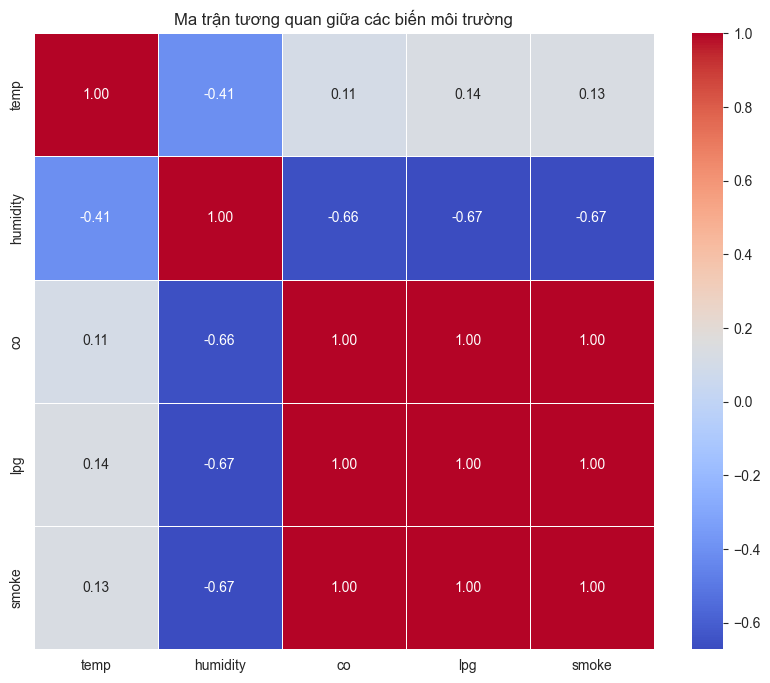

In [4]:
# Tính ma trận tương quan
corr_matrix = df[numerical_cols].corr()

# Vẽ Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến môi trường')
plt.show()

# Phần 2: Tiền xử lý dữ liệu

### Làm sạch dữ liệu bằng IQR

In [5]:
# LÀM SẠCH DỮ LIỆU (DATA CLEANING)

# 1. Tính toán IQR (Interquartile Range) cho Nhiệt độ và Độ ẩm
# Q1: Tứ phân vị thứ 1 (25%), Q3: Tứ phân vị thứ 3 (75%)
Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

# 2. Xác định biên dưới (Lower Bound) và biên trên (Upper Bound)
# Bất kỳ điểm nào nằm ngoài khoảng này được coi là Nhiễu (Outlier)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Lọc dữ liệu: Chỉ giữ lại các dòng nằm trong khoảng an toàn
# Lưu ý: Ta lọc chủ yếu trên temp và humidity vì đây là 2 thông số môi trường chính
condition = (
    (df['temp'] >= lower_bound['temp']) & (df['temp'] <= upper_bound['temp']) &
    (df['humidity'] >= lower_bound['humidity']) & (df['humidity'] <= upper_bound['humidity'])
)

df_cleaned = df[condition].copy()   # giữ lại những dòng nào thỏa mãn điều kiện condition

# In kết quả
rows_removed = len(df) - len(df_cleaned)
print(f"Số lượng dòng nhiễu bị loại bỏ bằng phương pháp IQR: {rows_removed}")
print(f"Dữ liệu còn lại: {len(df_cleaned)} dòng.")

Số lượng dòng nhiễu bị loại bỏ bằng phương pháp IQR: 8656
Dữ liệu còn lại: 396528 dòng.


### Biến đổi dữ liệu và Tạo đặc trưng mới (Feature Engineering)
xử lý thời gian, mã hóa dữ liệu chữ sang số, và tính toán Điểm sương (Dew Point) - một đặc trưng quan trọng cho bài toán nông nghiệp.

In [6]:
# --- BIẾN ĐỔI DỮ LIỆU (DATA TRANSFORMATION) ---
from sklearn.preprocessing import LabelEncoder

# 1. Xử lý thời gian (Time Transformation)
# Chuyển đổi timestamp sang datetime
df_cleaned['datetime'] = pd.to_datetime(df_cleaned['ts'], unit='s')     # unit='s': Chuyển giá trị timestamp tính theo giây thành ngày giờ thực tế
# Sắp xếp lại theo thời gian để chuẩn bị cho bước làm trơn (Smoothing) phía sau
df_cleaned = df_cleaned.sort_values('datetime')

# Tách các đặc trưng thời gian
df_cleaned['hour'] = df_cleaned['datetime'].dt.hour     # mấy giờ? để đoán xem lúc đó nóng hay lạnh
df_cleaned['is_day'] = df_cleaned['hour'].apply(lambda x: 1 if 6 <= x < 18 else 0)  # tạo cột ngày hay đêm?
# cột datetime là chuỗi kí tự dài gần như duy nhất. K-Means không thể tính khoảng cách

# 2. Chuyển đổi Boolean (True/False) sang 0/1
bool_cols = ['light', 'motion']
for col in bool_cols:
    df_cleaned[col] = df_cleaned[col].astype(int)

# 3. Kỹ nghệ đặc trưng (Feature Engineering): Tính Điểm Sương (Dew Point)
# Công thức Magnus-Tetens
def calculate_dew_point(temp, humidity):
    RH = humidity / 100.0
    a = 17.27
    b = 237.7
    gamma = (a * temp) / (b + temp) + np.log(RH)
    dew_point = (b * gamma) / (a - gamma)
    return dew_point

df_cleaned['dew_point'] = calculate_dew_point(df_cleaned['temp'], df_cleaned['humidity'])

print("Đã hoàn tất biến đổi thời gian, mã hóa và tính điểm sương.")
display(df_cleaned[['datetime', 'temp', 'humidity', 'dew_point']].head())

Đã hoàn tất biến đổi thời gian, mã hóa và tính điểm sương.


,datetime,temp,humidity,dew_point
0,2020-07-12 00:01:34.385974528,22.700000,51.000000,12.033225
1,2020-07-12 00:01:34.735567616,19.700001,76.000000,15.345602
2,2020-07-12 00:01:38.073572864,22.600000,50.900000,11.911455
3,2020-07-12 00:01:39.589145856,27.000000,76.800003,22.570000
4,2020-07-12 00:01:41.761234944,22.600000,50.900000,11.911455


In [7]:
df_cleaned.head()

,ts,device,co,humidity,light,lpg,motion,smoke,temp,datetime,hour,is_day,dew_point
0,1.594512e+09,b8:27:eb:bf:9d:51,0.004956,51.000000,0,0.007651,0,0.020411,22.700000,2020-07-12 00:01:34.385974528,0,0,12.033225
1,1.594512e+09,00:0f:00:70:91:0a,0.002840,76.000000,0,0.005114,0,0.013275,19.700001,2020-07-12 00:01:34.735567616,0,0,15.345602
2,1.594512e+09,b8:27:eb:bf:9d:51,0.004976,50.900000,0,0.007673,0,0.020475,22.600000,2020-07-12 00:01:38.073572864,0,0,11.911455
3,1.594512e+09,1c:bf:ce:15:ec:4d,0.004403,76.800003,1,0.007023,0,0.018628,27.000000,2020-07-12 00:01:39.589145856,0,0,22.570000
4,1.594512e+09,b8:27:eb:bf:9d:51,0.004967,50.900000,0,0.007664,0,0.020448,22.600000,2020-07-12 00:01:41.761234944,0,0,11.911455


### Làm trơn dữ liệu (Data Smoothing), One-Hot Encoding và Giảm chiều (Reduction)
Dữ liệu cảm biến thường bị "rung" (nhảy số liên tục). dùng Rolling Mean (trung bình trượt) để làm mượt đường biểu đồ. Sau đó loại bỏ các cột dư thừa.

In [8]:
# --- LÀM TRƠN (SMOOTHING) & ONE-HOT ENCODING ---
# Áp dụng Rolling Mean (Trung bình trượt) với cửa sổ window=5 mẫu
# Giúp giảm nhiễu ngẫu nhiên của cảm biến
cols_to_smooth = ['temp', 'humidity', 'smoke', 'dew_point']

# Lưu ý: Ta nhóm theo thiết bị trước khi làm trơn để tránh lẫn lộn dữ liệu giữa các thiết bị
df_cleaned[cols_to_smooth] = df_cleaned.groupby('device')[cols_to_smooth].transform(lambda x: x.rolling(window=5, min_periods=1).mean())
# Dữ liệu cảm biến (IoT) luôn chứa nhiễu (noise) do sự thay đổi tức thời của môi trường hoặc sai số thiết bị.
# window=5: lấy giá trị hiện tại cộng với 4 giá trị ngay trước đó (tổng là 5), rồi chia trung bình.
# min_periods=1: ở mấy dòng đầu tiên chưa đủ 5 số, thì có bao nhiêu tính bấy nhiêu

# 2. One-Hot Encoding cho cột Device
# prefix='dev' sẽ tạo ra các cột: dev_00:0f..., dev_1c:bf...
# Lệnh này tự động xóa cột 'device' gốc và thay bằng 3 cột mới
df_encoded = pd.get_dummies(df_cleaned, columns=['device'], prefix='dev')

# --- GIẢM NHẸ DỮ LIỆU (DATA REDUCTION) ---
# 1. Feature Selection: Loại bỏ co và lpg (do tương quan > 0.95 với smoke - xem Heatmap ở phần trước)
# 2. Loại bỏ các cột không còn dùng: ts, datetime (đã lấy hour)
drop_cols = ['co', 'lpg', 'ts', 'datetime']
df_final = df_encoded.drop(columns=drop_cols).dropna()

# --- CHUYỂN ĐỔI BOOLEAN VỀ SỐ NGUYÊN ---
# Chuyển các cột One-Hot vừa tạo thành số 0/1
dev_cols = [col for col in df_final.columns if col.startswith('dev_')]
for col in dev_cols:
    df_final[col] = df_final[col].astype(int)

print("Đã làm trơn dữ liệu và loại bỏ các cột dư thừa.")
print("Danh sách đặc trưng cuối cùng:", df_final.columns.tolist())

Đã làm trơn dữ liệu và loại bỏ các cột dư thừa.
Danh sách đặc trưng cuối cùng: ['humidity', 'light', 'motion', 'smoke', 'temp', 'hour', 'is_day', 'dew_point', 'dev_00:0f:00:70:91:0a', 'dev_1c:bf:ce:15:ec:4d', 'dev_b8:27:eb:bf:9d:51']


In [9]:
df_final.head()

,humidity,light,motion,smoke,temp,hour,is_day,dew_point,dev_00:0f:00:70:91:0a,dev_1c:bf:ce:15:ec:4d,dev_b8:27:eb:bf:9d:51
0,51.000000,0,0,0.020411,22.700000,0,0,12.033225,0,0,1
1,76.000000,0,0,0.013275,19.700001,0,0,15.345602,1,0,0
2,50.950000,0,0,0.020443,22.650000,0,0,11.972340,0,0,1
3,76.800003,1,0,0.018628,27.000000,0,0,22.570000,0,1,0
4,50.933333,0,0,0.020445,22.633333,0,0,11.952045,0,0,1


### Chuẩn hóa dữ liệu (Normalization)
Đưa tất cả về thang đo [0, 1] để thuật toán K-Means hoạt động chính xác nhất

In [10]:
# --- CHUẨN HÓA (NORMALIZATION) ---
from sklearn.preprocessing import MinMaxScaler

# Lấy danh sách tất cả các cột hiện có trong bảng
# (Bao gồm cả temp, humidity, smoke, dew_point, light, motion, dev_..., hour, is_day)
all_columns = df_final.columns.tolist()

# Khởi tạo Scaler
scaler = MinMaxScaler()

# Chuẩn hóa tất cả
df_final[all_columns] = scaler.fit_transform(df_final[all_columns])

print("Dữ liệu sau khi chuẩn hóa toàn bộ (Sẵn sàng cho K-Means):")
display(df_final.head())

Dữ liệu sau khi chuẩn hóa toàn bộ (Sẵn sàng cho K-Means):


,humidity,light,motion,smoke,temp,hour,is_day,dew_point,dev_00:0f:00:70:91:0a,dev_1c:bf:ce:15:ec:4d,dev_b8:27:eb:bf:9d:51
0,0.120180,0.0,0.0,0.369441,0.420290,0.0,0.0,0.153245,0.0,0.0,1.0
1,0.588169,0.0,0.0,0.176745,0.148551,0.0,0.0,0.408214,1.0,0.0,0.0
2,0.119244,0.0,0.0,0.370303,0.415761,0.0,0.0,0.148559,0.0,0.0,1.0
3,0.603145,1.0,0.0,0.321295,0.809783,0.0,0.0,0.964307,0.0,1.0,0.0
4,0.118932,0.0,0.0,0.370342,0.414251,0.0,0.0,0.146997,0.0,0.0,1.0


# Phần 3: Học máy & Đánh giá kết quả

### Tìm số cụm tối ưu (Elbow Method)

Đang chạy thử nghiệm để tìm K tối ưu...
- Với K=1, Inertia = 525680.43
- Với K=2, Inertia = 361951.03
- Với K=3, Inertia = 152387.11
- Với K=4, Inertia = 105356.53
- Với K=5, Inertia = 77181.75
- Với K=6, Inertia = 68677.67
- Với K=7, Inertia = 43784.13
- Với K=8, Inertia = 30916.83
- Với K=9, Inertia = 22412.76
- Với K=10, Inertia = 20826.25


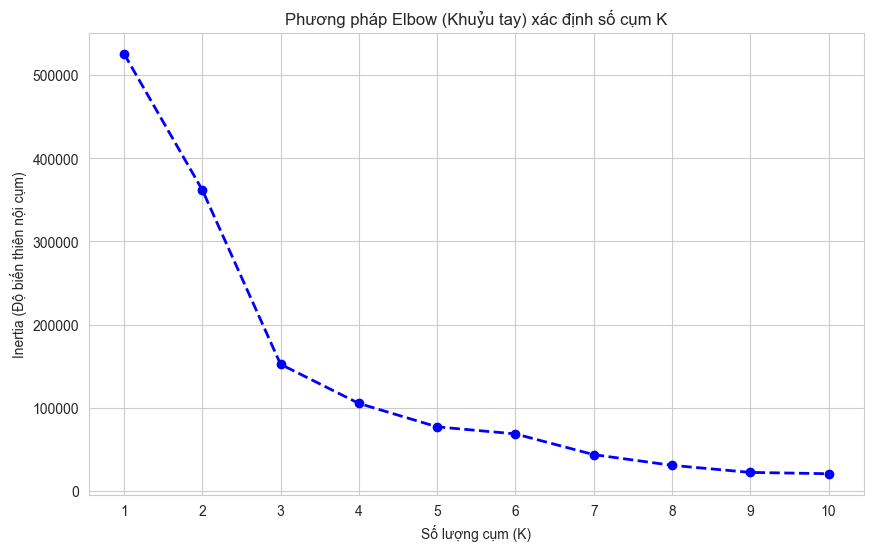

In [11]:
# BƯỚC 1: TÌM SỐ CỤM TỐI ƯU (ELBOW METHOD)
from sklearn.cluster import KMeans

# 1. Lấy dữ liệu đã chuẩn hóa (df_final) để đưa vào máy học
# (Máy học chỉ làm việc với số đã chuẩn hóa [0,1])
X = df_final.values 

# Danh sách chứa giá trị Inertia cho từng k
inertia = []
K_range = range(1, 11) # Thử từ 1 đến 10 cụm

# 2. Chạy vòng lặp (Trial & Error)
print("Đang chạy thử nghiệm để tìm K tối ưu...")
for k in K_range:
    # n_init='auto': Chạy thuật toán nhanh hơn, tự động chọn tâm khởi tạo tốt
    # random_state=42: Để kết quả lần nào chạy cũng giống nhau
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    print(f"- Với K={k}, Inertia = {kmeans.inertia_:.2f}")

# 3. Vẽ biểu đồ Elbow (Bắt buộc phải vẽ để chọn K)
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='b', linewidth=2)
plt.title('Phương pháp Elbow (Khuỷu tay) xác định số cụm K')
plt.xlabel('Số lượng cụm (K)')
plt.ylabel('Inertia (Độ biến thiên nội cụm)')
plt.xticks(K_range)		# Thiết lập vị trí tick
plt.grid(True)
plt.show()

### Thiết lập và Chạy mô hình K-Means (Modeling)

In [12]:
# BƯỚC 2: CHẠY THUẬT TOÁN K-MEANS

# 1. Chốt số cụm K = 3 (Dựa trên Elbow và bài toán thực tế: Tốt, Bình thường, Xấu)
optimal_k = 3

# 2. Khởi tạo mô hình chính thức
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')

# 3. Huấn luyện mô hình trên dữ liệu đã chuẩn hóa
print(f"Đang huấn luyện mô hình K-Means với K={optimal_k}...")
kmeans_model.fit(X)		# tìm ra 3 Centroids đại diện cho 3 trạng thái môi trường

# 4. Gán nhãn kết quả (Labels)
# labels_ là một danh sách chứa các số 0, 1, 2 tương ứng với từng dòng dữ liệu
cluster_labels = kmeans_model.labels_

# GÁN NHÃN VÀO DATAFRAME
# Ta gán nhãn vào df_cleaned (bảng chứa giá trị THỰC) để con người đọc hiểu
# Không gán vào df_final vì bảng đó toàn số 0.xxx khó hình dung
df_cleaned['cluster'] = cluster_labels

# Kiểm tra kết quả gán nhãn
print("\nĐã phân cụm xong! Xem 5 dòng đầu tiên có cột 'cluster':")
display(df_cleaned[['datetime', 'temp', 'humidity', 'smoke', 'cluster']].head())

print("\nSố lượng dữ liệu trong từng cụm:")
print(df_cleaned['cluster'].value_counts())

Đang huấn luyện mô hình K-Means với K=3...

Đã phân cụm xong! Xem 5 dòng đầu tiên có cột 'cluster':


,datetime,temp,humidity,smoke,cluster
0,2020-07-12 00:01:34.385974528,22.700000,51.000000,0.020411,0
1,2020-07-12 00:01:34.735567616,19.700001,76.000000,0.013275,2
2,2020-07-12 00:01:38.073572864,22.650000,50.950000,0.020443,0
3,2020-07-12 00:01:39.589145856,27.000000,76.800003,0.018628,1
4,2020-07-12 00:01:41.761234944,22.633333,50.933333,0.020445,0



Số lượng dữ liệu trong từng cụm:
cluster
0    187451
2    111601
1     97476
Name: count, dtype: int64


### Phân tích đặc điểm các cụm (Cluster Summary)
1. Cụm nào có 'smoke' cao nhất -> Khả năng là "Cảnh báo/Nguy hiểm"
2. Cụm nào có 'temp' thấp, 'humidity' cao -> Khả năng là "Mát mẻ/Tốt"
3. Cụm còn lại thường là "Bình thường"

In [13]:
# BƯỚC 2 (TIẾP): PHÂN TÍCH ĐẶC ĐIỂM CỤM (SUMMARY)

# Chọn các cột quan trọng để soi (Nhiệt độ, Độ ẩm, Khói, Điểm sương, Ban ngày/đêm)
analysis_cols = ['temp', 'humidity', 'smoke', 'dew_point', 'is_day']

# Tính giá trị trung bình (Mean) của từng cụm
# Lệnh này trả lời câu hỏi: "Trung bình thì nhóm 0 nóng bao nhiêu độ? Nhóm 1 ẩm bao nhiêu?"
cluster_summary = df_cleaned.groupby('cluster')[analysis_cols].mean()

print("=== BẢNG ĐẶC ĐIỂM CỦA 3 TRẠNG THÁI MÔI TRƯỜNG ===")
display(cluster_summary)

=== BẢNG ĐẶC ĐIỂM CỦA 3 TRẠNG THÁI MÔI TRƯỜNG ===


,temp,humidity,smoke,dew_point,is_day
cluster,,,,,
0,22.279974,50.814104,0.022288,11.581583,0.499891
1,25.723661,62.417290,0.017881,17.845978,0.532418
2,19.385063,75.456648,0.015489,14.924011,0.503974


### Trực quan hóa kết quả bằng PCA
nén tất cả lại thành 2 trục (PC1, PC2) để vẽ thành biểu đồ chấm 2D để thấy 3 nhóm tách nhau ra thế nào

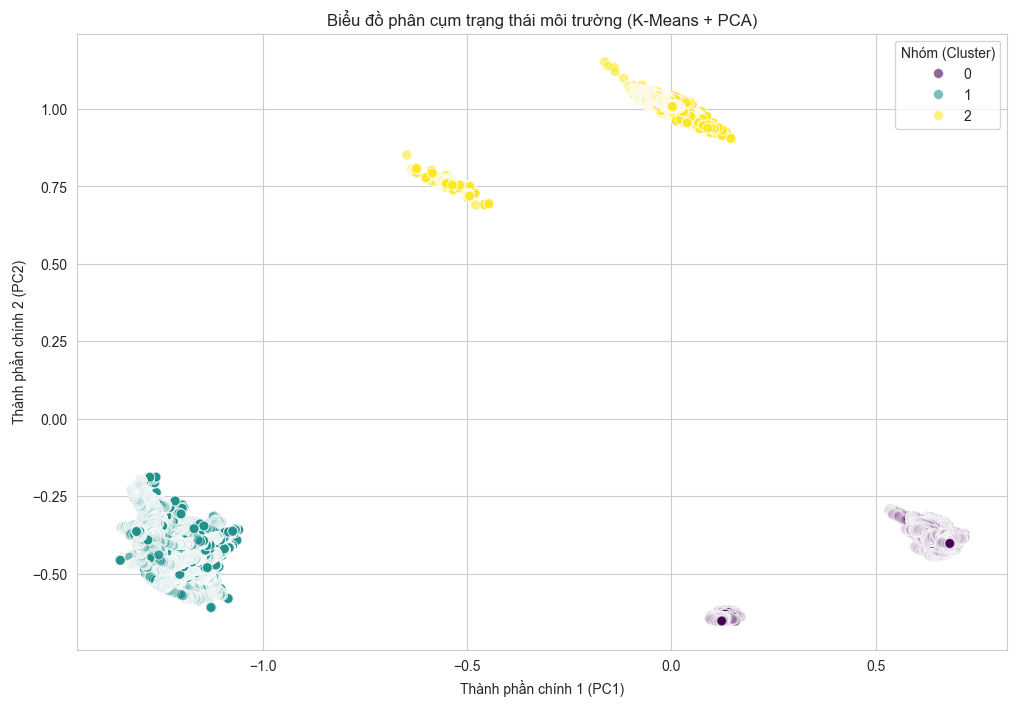

In [14]:
# BƯỚC 3: TRỰC QUAN HÓA BẰNG PCA
from sklearn.decomposition import PCA
import seaborn as sns

# 1. Nén dữ liệu xuống 2 chiều (2D) để vẽ
# Dùng X (dữ liệu đã chuẩn hóa)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# 2. Tạo bảng tạm để vẽ
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = kmeans_model.labels_

# 3. Vẽ biểu đồ
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Cluster',          # tô màu các điểm dựa theo cột Cluster
    data=pca_df, 
    palette='viridis',      # Bảng màu
    s=50,                   # size chấm tròn
    alpha=0.6               # Độ trong suốt của điểm
)
plt.title('Biểu đồ phân cụm trạng thái môi trường (K-Means + PCA)')
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.legend(title='Nhóm (Cluster)')      # khung chú thích bên cạnh biểu đồ
plt.grid(True)
plt.show()

### Đánh giá và Đặt tên định danh cho các cụm (Evaluation)

=== KẾT QUẢ PHÂN LOẠI TRẠNG THÁI MÔI TRƯỜNG ===


,datetime,device,temp,humidity,smoke,Trạng_thái
0,2020-07-12 00:01:34.385974528,b8:27:eb:bf:9d:51,22.700000,51.000000,0.020411,Cảnh báo (Khô & Khói cao)
1,2020-07-12 00:01:34.735567616,00:0f:00:70:91:0a,19.700001,76.000000,0.013275,Mát mẻ & Ẩm ướt (Tốt)
2,2020-07-12 00:01:38.073572864,b8:27:eb:bf:9d:51,22.650000,50.950000,0.020443,Cảnh báo (Khô & Khói cao)
3,2020-07-12 00:01:39.589145856,1c:bf:ce:15:ec:4d,27.000000,76.800003,0.018628,Bình thường (Ấm áp)
4,2020-07-12 00:01:41.761234944,b8:27:eb:bf:9d:51,22.633333,50.933333,0.020445,Cảnh báo (Khô & Khói cao)
5,2020-07-12 00:01:44.468410624,1c:bf:ce:15:ec:4d,27.000000,77.350002,0.018609,Bình thường (Ấm áp)
6,2020-07-12 00:01:45.448863488,b8:27:eb:bf:9d:51,22.625000,50.925000,0.020452,Cảnh báo (Khô & Khói cao)
7,2020-07-12 00:01:46.869075968,00:0f:00:70:91:0a,19.700001,76.000000,0.013451,Mát mẻ & Ẩm ướt (Tốt)
8,2020-07-12 00:01:48.275381504,1c:bf:ce:15:ec:4d,27.000000,77.533335,0.018552,Bình thường (Ấm áp)
9,2020-07-12 00:01:49.136686848,b8:27:eb:bf:9d:51,22.620000,50.920000,0.020453,Cảnh báo (Khô & Khói cao)


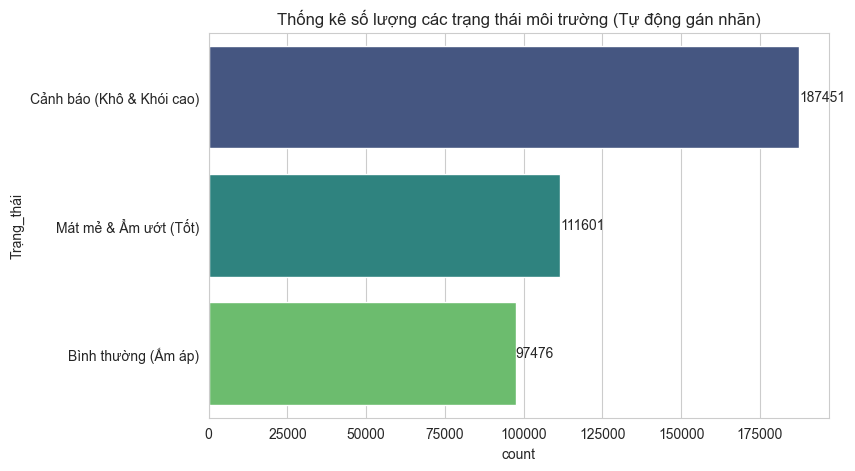

In [15]:
# --- BƯỚC 4 (CẬP NHẬT): TỰ ĐỘNG ĐẶT TÊN CỤM ---
# Cách này giúp code chạy trên mọi máy đều đúng, không lo bị đảo lộn số 0, 1, 2

# 1. Tính trung bình đặc điểm các cụm (để máy tự soi)
cluster_means = df_cleaned.groupby('cluster')[['temp', 'humidity', 'smoke']].mean()

# 2. Định nghĩa logic để máy tự tìm:
# - Tìm cụm có Khói (smoke) cao nhất -> Gán là "Cảnh báo"
idx_danger = cluster_means['smoke'].idxmax()

# - Tìm cụm có Nhiệt độ (temp) thấp nhất -> Gán là "Mát mẻ"
idx_cool = cluster_means['temp'].idxmin()

# - Cụm còn lại -> Gán là "Bình thường"
# (Lấy tập hợp {0,1,2} trừ đi 2 thằng kia là ra thằng còn lại)
all_clusters = set(cluster_means.index)
idx_normal = list(all_clusters - {idx_danger, idx_cool})[0]

# 3. Tạo từ điển tên dựa trên logic vừa tìm
dynamic_cluster_names = {
    idx_danger: 'Cảnh báo (Khô & Khói cao)',    # Smoke cao nhất, Humidity thấp
    idx_cool:   'Mát mẻ & Ẩm ướt (Tốt)',        # Temp thấp, Humidity cao
    idx_normal: 'Bình thường (Ấm áp)'           # Temp cao
}

# 4. Gán tên vào DataFrame
df_cleaned['Trạng_thái'] = df_cleaned['cluster'].map(dynamic_cluster_names)
# In kết quả cuối cùng
print("=== KẾT QUẢ PHÂN LOẠI TRẠNG THÁI MÔI TRƯỜNG ===")
display(df_cleaned[['datetime', 'device', 'temp', 'humidity', 'smoke', 'Trạng_thái']].head(10))

# 5. Vẽ biểu đồ kết quả
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    y='Trạng_thái', 
    data=df_cleaned, 
    hue='Trạng_thái', 
    palette='viridis', 
    order=df_cleaned['Trạng_thái'].value_counts().index,
    dodge=False 
    # legend=False          # Tắt chú thích thừa
)

plt.title('Thống kê số lượng các trạng thái môi trường (Tự động gán nhãn)')

# Hiện số trên đầu cột
for container in ax.containers:
    ax.bar_label(container)
plt.show()